# 11 — Figuras para el video de avance #1 (EDA)

**Autor:** Jason Sepúlveda S.
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [`03-jss-eda.ipynb`](03-jss-eda.ipynb)

---

## Qué hace este notebook

El [notebook 03](03-jss-eda.ipynb) contiene el análisis exploratorio completo, con 20 figuras pensadas
para leerse en pantalla de computador y ninguna guardada como archivo. Este notebook elige, entre
ellas, las pocas que sirven para el **video de avance #1**, las vuelve a generar con letra grande
para una grabación de pantalla y las exporta como imágenes PNG a
[`docs/entregables/figuras/`](../docs/entregables/figuras/), de modo que el guion del video pueda
incrustarlas.

No se calcula nada nuevo: cada tabla viene de funciones testeadas de `afg.eda`, las mismas que usa el
notebook 03, y los dibujos salen de `afg.eda.figures`.

## Qué pide el video

Según la **rúbrica del video de avance #1**:

- **Duración:** máximo 8 minutos, con diapositivas como material de apoyo recomendado.
- **Objetivo:** una primera aproximación a los datos del proyecto: cómo se organizan, limpian o
  exploran, y qué hallazgos iniciales, dificultades o preguntas orientarán el EDA posterior.
- **Nivel "logrado":** muestra con claridad los primeros pasos con los datos (organización, limpieza
  inicial, visualizaciones de ejemplo o estadísticas descriptivas), señala hallazgos preliminares y
  dificultades encontradas, y explica cómo influyen en los siguientes pasos del proyecto.
- **Riesgo a evitar** (nivel "parcialmente logrado"): describir los datos sin conectarlos con el
  problema de investigación, o dejar los hallazgos limitados o mal interpretados.

Con ocho minutos caben **cuatro figuras, cinco como máximo**. Se preparan **cinco, todas del conjunto
principal**; si el guion no alcanza, la figura 3 es la más prescindible. El orden de abajo sigue la
historia del video: qué son los datos, qué problema de calidad tienen, qué se ve al describirlos, cómo
se llega a los pares que se anotan y qué dificultad aparece para lo que viene.

## Criterios de selección

El **problema de investigación** es si recordar las decisiones de una serie de reuniones en una
estructura persistente responde mejor que recuperar fragmentos del texto, sobre todo cuando una
decisión cambia entre reuniones. Una figura entra si cumple al menos uno de los criterios de la rúbrica
y, además, se puede conectar con ese problema.

| # | Criterio (rúbrica) | Pregunta que debe responder la figura | Figura elegida |
|---|---|---|---|
| 1 | Organización de los datos | ¿Qué datos hay y cómo están organizados? | Figura 1 |
| 2 | Limpieza inicial o problema de calidad | ¿Qué falta o es dudoso, y qué se hace al respecto? | Figura 2 |
| 3 | Visualización descriptiva con un hallazgo preliminar | ¿Qué se observa al describir los datos? | Figura 3 |
| 4 | Decisión metodológica clave (cómo se obtienen los pares a anotar) | ¿Cómo se pasa de 3.071 pares a los 92 que se anotan, y a qué costo? | Figura 4 |
| 5 | Dificultad encontrada y su consecuencia | ¿Qué obstáculo aparece para el experimento y qué cambia en los pasos siguientes? | Figura 5 |

Criterios de apoyo: un solo mensaje por figura, legible a distancia, y que la cifra mostrada esté
respaldada por el notebook 03. Como el curso espera en esta semana un EDA **inicial** que enmarque los
datos y deje lo secundario para anexos, el análisis completo (correlaciones, agrupamiento, sensibilidad
del filtro) no entra en el video.

La rúbrica no pide mostrar valores atípicos y la comparación de las dos figuras posibles dejó fuera la
de atípicos (ver «Figuras del notebook 03 que quedan fuera»): la decisión sobre ellos sigue documentada
en el notebook 03, §5.


In [1]:
import numpy as np

from afg import audit, eda
from afg.annotation.blocking import (
    decisions_from_abstractive,
    generate_candidates,
    jaccard,
    tokenize,
)
from afg.audit import candidate_funnel, funnel_hours
from afg.eda.figures import (
    plot_funnel,
    plot_level_sizes,
    plot_position_boxes,
    plot_rate_by_bin,
    plot_rate_lines,
    save_figure,
    video_style,
)
from afg.shared.config import load_corpus_config
from afg.shared.paths import AMI_DIR, PROJECT_ROOT

SEED = 0  # kept for reproducibility of any seeded step inside afg.eda
np.random.seed(SEED)

FIGURES_DIR = PROJECT_ROOT / "docs" / "entregables" / "figuras"

# Guard: the corpus is gitignored.
if not AMI_DIR.exists() or not any(AMI_DIR.glob("abstractive/*.xml")):
    raise SystemExit("Falta el corpus AMI. Ejecuta primero: uv run afg corpus download")

TABLES = eda.load_eda_tables()
SERIES_T, MEETING, SPEAKER = TABLES.series, TABLES.meeting, TABLES.speaker_meeting
DECISION, PAIR = TABLES.decision, TABLES.pair
EXPORTED = []  # paths of the exported PNGs, in the order they are saved
print(
    f"Niveles cargados: serie {len(SERIES_T)}, reunión {len(MEETING)}, "
    f"hablante-reunión {len(SPEAKER)}, decisión {len(DECISION)}, par {len(PAIR)}"
)

Niveles cargados: serie 14, reunión 56, hablante-reunión 224, decisión 343, par 3071


---

# Figura 1 — Cómo están organizados los datos

*Criterio 1 (organización).*

{'Serie (4 reuniones)': 14, 'Reunión': 56, 'Hablante en una reunión': 224, 'Decisión': 343, 'Par de decisiones': 3071}


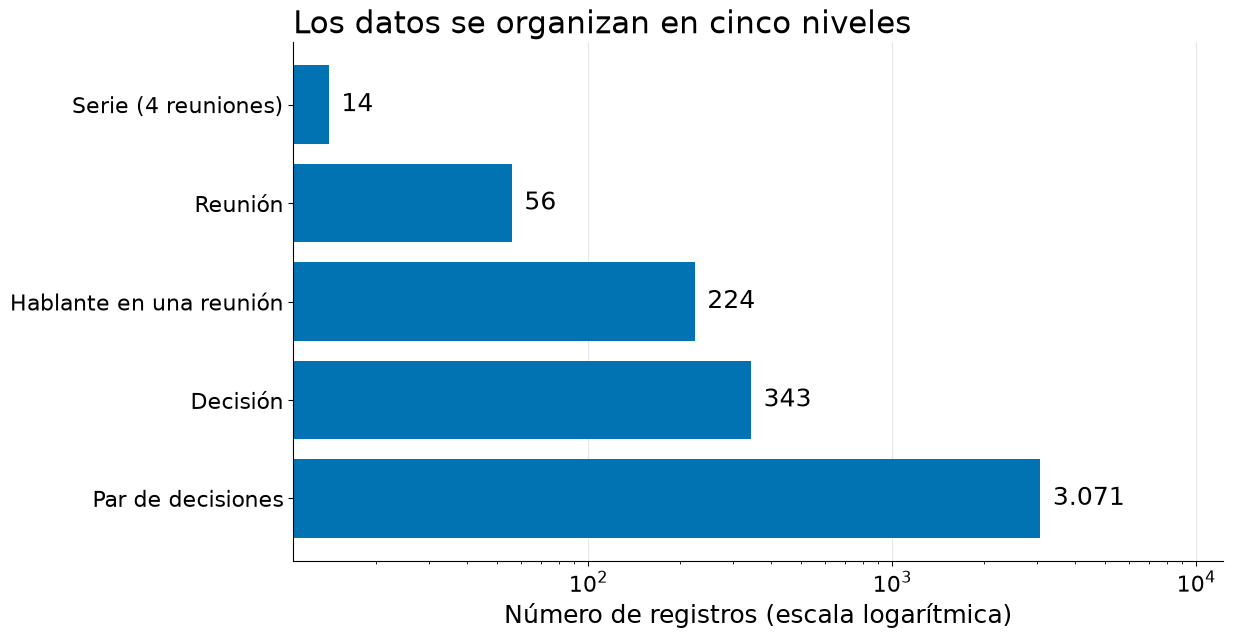

In [2]:
LEVEL_SIZES = {
    "Serie (4 reuniones)": len(SERIES_T),
    "Reunión": len(MEETING),
    "Hablante en una reunión": len(SPEAKER),
    "Decisión": len(DECISION),
    "Par de decisiones": len(PAIR),
}
with video_style():
    fig = plot_level_sizes(LEVEL_SIZES, title="Los datos se organizan en cinco niveles")
    path = save_figure(fig, FIGURES_DIR / "eda-estructura-de-los-datos.png")
EXPORTED.append(path)
print(LEVEL_SIZES)

**Por qué esta figura.** Es la primera pregunta de cualquier revisor: qué hay. Resume en una sola imagen
las 14 series del corpus AMI, sus 56 reuniones y los registros derivados de ellas, desde los hablantes
hasta los pares de decisiones. Responde al criterio de organización y evita explicar tablas una por una.

**Mensaje en pantalla.** Los datos son pocos al nivel de la serie (14) pero numerosos al nivel del par
(3.071): ahí se concentra el trabajo.

**Cómo influye en los siguientes pasos.** El problema se juega en los pares de decisiones de reuniones
distintas de una misma serie. Con solo 14 series, cualquier conclusión debe apoyarse en la serie como
unidad y no solo en la cantidad de pares.

*Origen en el notebook 03: §1.2 (niveles de análisis) y §2.1.*

---

# Figura 2 — Un problema de calidad: decisiones sin evidencia

*Criterio 2 (limpieza inicial / calidad).*

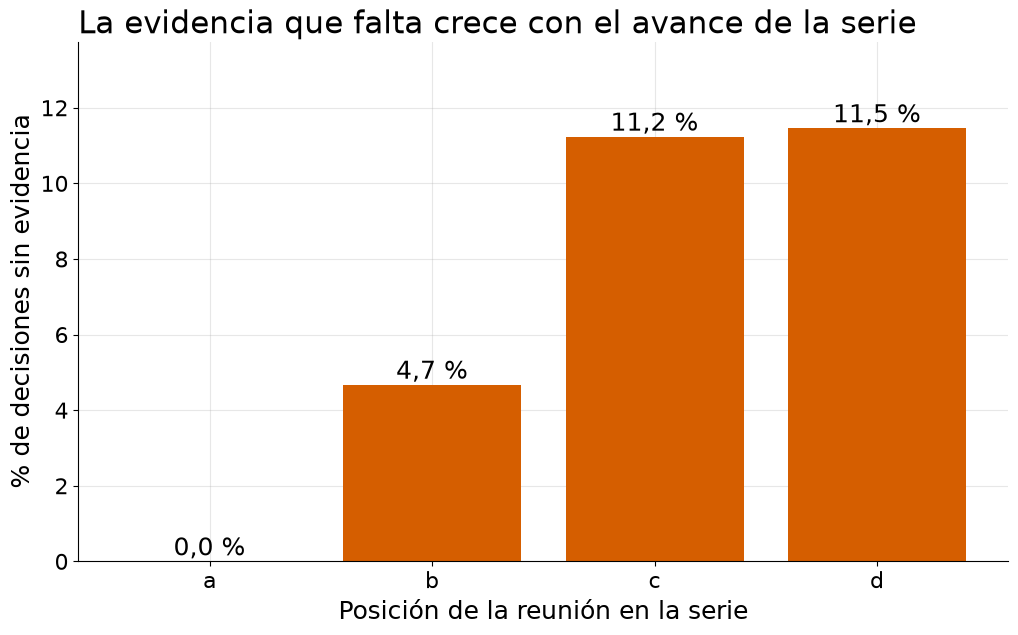

Decisiones sin evidencia: 26 de 343


,bin,n,n_true,rate
0,a,51,0,0.000
1,b,107,5,0.047
2,c,89,10,0.112
3,d,96,11,0.115


In [3]:
NO_EVIDENCE = DECISION.assign(no_evidence=~DECISION["anchored"])
RATE_NO_EVIDENCE = eda.rate_by_bin(
    NO_EVIDENCE, "position_index", "no_evidence", [0, 1, 2, 3, 4], labels=list("abcd")
)
with video_style():
    fig = plot_rate_by_bin(
        RATE_NO_EVIDENCE,
        xlabel="Posición de la reunión en la serie",
        ylabel="% de decisiones sin evidencia",
        title="La evidencia que falta crece con el avance de la serie",
    )
    path = save_figure(fig, FIGURES_DIR / "eda-decisiones-sin-evidencia-por-posicion.png")
    display(fig)
EXPORTED.append(path)
print(f"Decisiones sin evidencia: {int(NO_EVIDENCE['no_evidence'].sum())} de {len(DECISION)}")
display(RATE_NO_EVIDENCE.round(3))

**Por qué esta figura.** De las tres variables con celdas vacías en todo el conjunto, esta es la que
importa para el problema: una decisión sin actos de evidencia no se puede rastrear hasta la
conversación que la originó. Muestra además la política de limpieza del proyecto: no se imputa ni se
elimina nada, solo se marca (notebook 03, §3.4 y §11.2).

**Mensaje en pantalla.** 26 de 343 decisiones carecen de evidencia, y la proporción pasa de 0 % en la
primera reunión a cerca de 11 % en la tercera y la cuarta.

**Cómo influye en los siguientes pasos.** Las etiquetas de referencia las pone una persona, así que no se
estima la evidencia faltante. En su lugar, esas 26 decisiones se revisan con cuidado durante la
adjudicación: el único error de origen conocido en los datos (el resumen que afirma que se elimina el
botón turbo) tiene justamente evidencia cero.

*Origen en el notebook 03: §3.1 a §3.4, §5.5 y hallazgo 3 de §11.1.*

---

# Figura 3 — Primer hallazgo descriptivo: la primera reunión tiene pocas decisiones

*Criterio 3 (visualización descriptiva con hallazgo preliminar).*

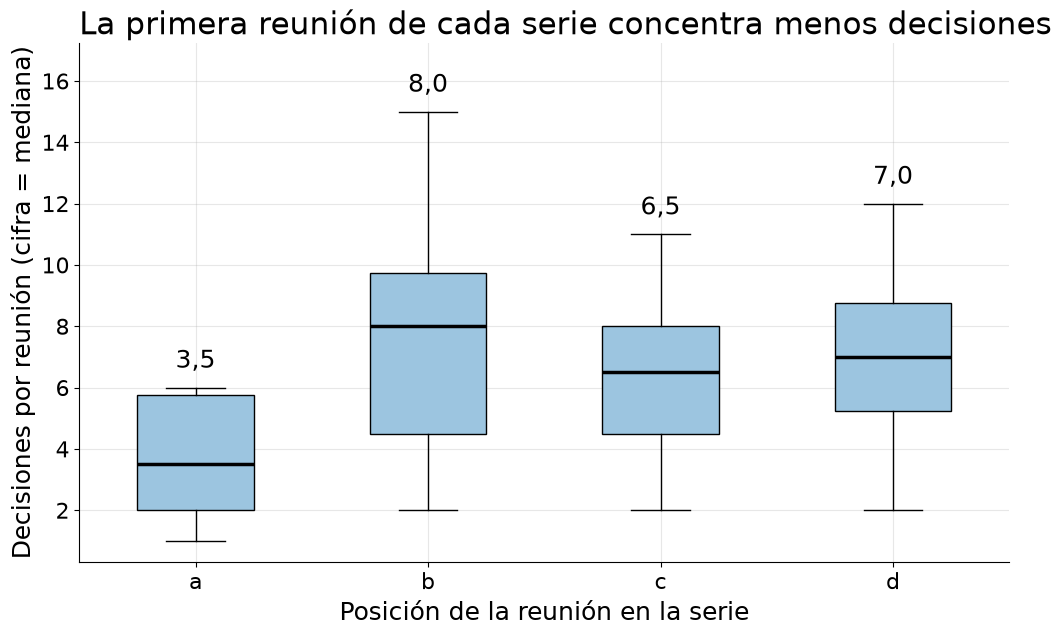

,count,mean,median
position,,,
a,14,3.64,3.5
b,14,7.64,8.0
c,14,6.36,6.5
d,14,6.86,7.0


In [4]:
with video_style():
    fig = plot_position_boxes(
        MEETING,
        "n_decisions",
        ylabel="Decisiones por reunión (cifra = mediana)",
        title="La primera reunión de cada serie concentra menos decisiones",
    )
    path = save_figure(fig, FIGURES_DIR / "eda-decisiones-por-posicion.png")
    display(fig)
EXPORTED.append(path)
display(MEETING.groupby("position")["n_decisions"].agg(["count", "mean", "median"]).round(2))

**Por qué esta figura.** Es una estadística descriptiva simple que se entiende sin conocimientos
técnicos y que ya conecta con el problema: si las decisiones que cambian se reparten entre reuniones,
importa dónde ocurren.

**Cómo leer el gráfico.** Es un diagrama de caja. Cada caja contiene a la mitad central de las
reuniones de esa posición; la línea gruesa es la **mediana**, el valor que deja la mitad de las
reuniones por debajo y la otra mitad por encima, y las líneas verticales llegan hasta los casos más
bajos y más altos. La cifra sobre cada caja es la mediana.

**Mensaje en pantalla.** La reunión a tiene la mitad de decisiones que las demás: la mediana es de 3,5
decisiones por reunión frente a 8,0, 6,5 y 7,0 en las reuniones b, c y d. De la b a la d el nivel es
parecido. (Los promedios, de 3,6 frente a 7,6, 6,4 y 6,9, cuentan la misma historia; en el notebook 03,
§9, se informan ambos.)

**Cómo influye en los siguientes pasos.** Las preguntas sobre cómo evoluciona una decisión se apoyarán
sobre todo en las reuniones b, c y d. Queda abierta una pregunta: si el quiebre refleja el diseño del
escenario (una primera reunión más breve) o un cambio real en la actividad; con estos datos no se
pueden distinguir ambas lecturas.

*Origen en el notebook 03: §9 (análisis temporal), pregunta P4 y hallazgo 8 de §11.1.*

---

# Figura 4 — Cómo se llega a los 92 pares que se anotan

*Criterio 4 (decisión metodológica clave).*

## Cómo funciona el filtro, paso a paso

**1. El problema.** En cada serie de 4 reuniones se toman decisiones (por ejemplo, "el control tendrá
un botón turbo"). El conjunto de referencia necesita pares de decisiones de reuniones distintas,
revisados y etiquetados por una persona: ¿una cambia, revierte o repite a la otra? Si se combina cada
decisión con todas las de las otras reuniones de su serie, salen **3.071 pares**. A 1,5 minutos por
par son **≈ 77 horas** de anotación, y la gran mayoría de esos pares no tiene relación alguna
("el control será amarillo" frente a "la reunión termina a las 5").

**2. La idea.** Si dos decisiones hablan de lo mismo, probablemente **comparten palabras**. Antes de que
una persona mire un par, una regla automática descarta los que casi no comparten palabras. Es un
filtro **léxico** (solo mira palabras) y también se le llama **bloqueo**. El filtro **no asigna la
etiqueta**: solo decide qué pares vale la pena que una persona revise.

**3. Cómo se preparan las frases.** Cada decisión se pasa a minúsculas, se conservan solo las palabras
de 3 letras o más y se eliminan las **palabras vacías** ("de", "que", "el"; en el corpus, "the",
"and"…), que aparecen en todas las frases y no dicen nada del tema. Lo que queda son las **palabras de
contenido**.

**4. El coeficiente de solapamiento.**

$$\text{solapamiento}(A, B) = \frac{\text{palabras compartidas}}{\text{palabras de la frase más corta}}$$

Responde a la pregunta: *¿qué parte de la frase corta está contenida en la larga?*

> *Ejemplo ilustrativo (en español; el corpus está en inglés).* Frase A, larga: "el control tendrá
> rueda de desplazamiento, pantalla, botón turbo, botón de encendido y carcasa amarilla" (10 palabras
> de contenido). Frase B, corta: "se elimina el botón turbo" (3: *elimina, botón, turbo*). Comparten 2
> (*botón, turbo*). Solapamiento = 2 / 3 = **0,67** ≥ 0,30: el par pasa.

**5. Por qué no Jaccard, la medida más común.** Jaccard divide por **todas** las palabras distintas de
las dos frases: en el ejemplo, 2 / (10 + 3 − 2) = 2 / 11 = **0,18**, y el par se pierde. Una reversión
suele ser una **frase corta posterior que apunta a una larga anterior**; Jaccard castiga justo esa
diferencia de largo, porque la frase larga "diluye" a la corta. Un filtro con Jaccard dejaría al
proyecto ciego a las reversiones, que son lo que se quiere medir. El caso real del corpus (el par del
botón turbo de IS1004: Jaccard 0,118, solapamiento 0,400) se calcula más abajo.

**6. Por qué además se exigen 2 palabras en común.** El solapamiento se infla solo con **frases muy
cortas**.

> *Ejemplo ilustrativo.* Frase B: "cambiar color" (2 palabras de contenido). Frase A: "el color del
> logo es azul". Comparten 1 (*color*). Solapamiento = 1 / 2 = **0,50**: el par pasa sin tener relación.

Una coincidencia suelta puede ser casualidad; dos ya indican que las frases hablan de lo mismo. Por eso
un par es candidato solo si el coeficiente es **≥ 0,30 y** comparte **al menos 2 palabras**.

**7. Por qué 0,30 y 2.** El punto está acotado por los dos lados: si se relaja, vuelven los 712 pares
(≈ 18 h); si se endurece (umbral sobre 0,40 o 3 palabras), **se pierde el par del botón turbo**, el
único caso de reversión revisado a mano.

**8. Beneficio.** De ≈ 77 h a ≈ 2,3 h de anotación humana; las personas dedican su tiempo a pares con
probabilidad real de estar relacionados; la regla es simple, explicable y reproducible (código con
tests en `src/afg/annotation/blocking.py`).

**9. Riesgos declarados.** (1) Se pierden las **paráfrasis**: dos frases que dicen lo mismo con otras
palabras ("quitar el turbo" frente a "sacar la función de velocidad"). (2) Se penaliza a las frases
muy cortas, y las reversiones tienden a serlo. (3) El punto de operación se calibró con **un solo** par
de control. (4) El presupuesto de horas influyó en su elección. (5) El conjunto de referencia favorece
a los métodos que trabajan con palabras. Por todo esto, **92 es lo máximo que este filtro deja anotar,
no el número de relaciones que existen en el corpus**.

**10. Cómo se mitiga: la Tarea C.** Se toman al azar, con semilla fija, 50 pares por serie entre los
que el filtro **rechazó**, se anotan con las mismas reglas y se cuenta cuántas relaciones reales había
ahí. Eso mide el **recall** del filtro (de todas las relaciones que existen, qué proporción deja pasar).
La muestra está generada; falta anotarla.


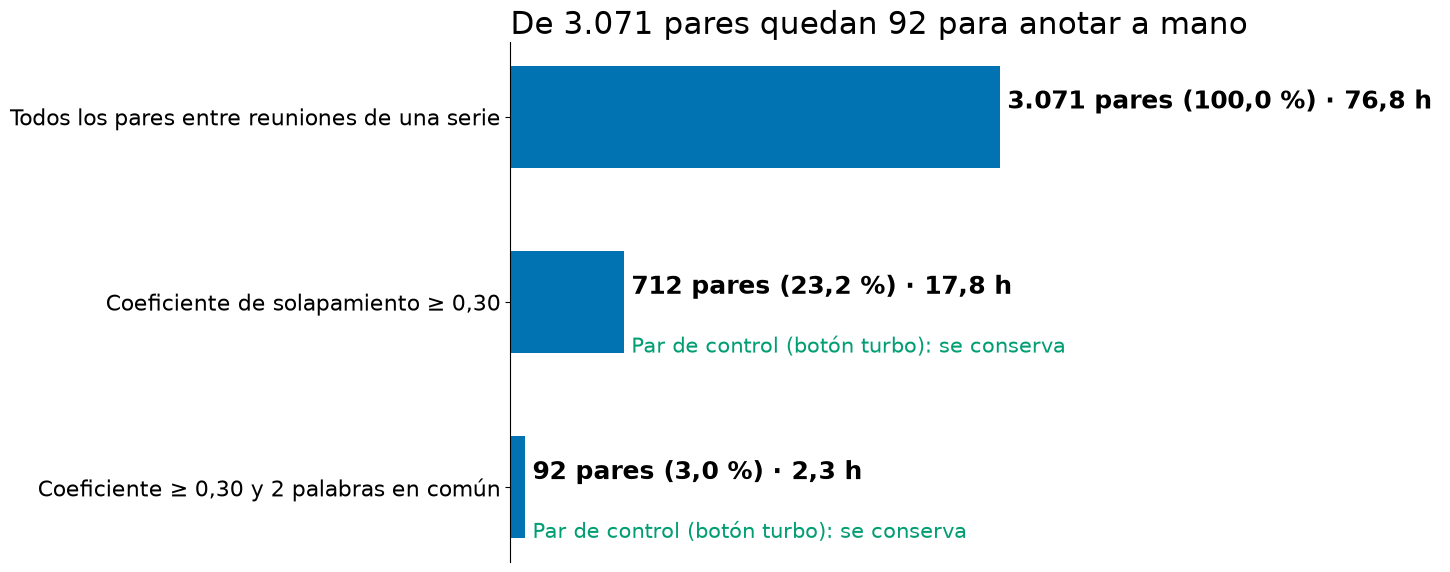

{'Todos los pares entre reuniones de una serie': (3071, 76.8), 'Coeficiente de solapamiento ≥ 0,30': (712, 17.8), 'Coeficiente ≥ 0,30 y 2 palabras en común': (92, 2.3)}


In [5]:
SERIES_IDS = load_corpus_config()["oe1"]["series"]
FUNNEL_COUNTS = candidate_funnel(AMI_DIR, SERIES_IDS)
N_ALL, N_COEF, N_FULL = FUNNEL_COUNTS.counts
assert (N_ALL, N_COEF, N_FULL) == (3071, 712, 92), (N_ALL, N_COEF, N_FULL)  # figures quoted in D9
assert len(PAIR) == N_ALL  # same universe as the EDA pair table
FUNNEL = {
    "Todos los pares entre reuniones de una serie": N_ALL,
    "Coeficiente de solapamiento ≥ 0,30": N_COEF,
    "Coeficiente ≥ 0,30 y 2 palabras en común": N_FULL,
}
HOURS = funnel_hours(list(FUNNEL.values()))
TURBO = [None, FUNNEL_COUNTS.turbo_survives_coefficient, FUNNEL_COUNTS.turbo_survives_full]
assert TURBO == [None, True, True]  # the control pair survives the chosen operating point
with video_style():
    fig = plot_funnel(
        FUNNEL,
        hours=HOURS,
        control_survives=TURBO,
        control_label="Par de control (botón turbo)",
        title="De 3.071 pares quedan 92 para anotar a mano",
    )
    path = save_figure(fig, FIGURES_DIR / "eda-embudo-del-filtro-lexico.png")
    display(fig)
EXPORTED.append(path)
print({k: (n, round(h, 1)) for (k, n), h in zip(FUNNEL.items(), HOURS, strict=True)})

**Por qué esta figura.** Es la decisión metodológica que más condiciona el proyecto: anotar los 3.071 pares
a mano no es viable (≈ 77 horas), así que un filtro de palabras elige cuáles ven las personas. La
figura muestra qué se descarta, cuánto trabajo se ahorra (de ≈ 18 h a ≈ 2,3 h con la segunda condición)
y que el único caso de reversión revisado a mano sigue dentro. Las horas salen de un ritmo de 1,5
minutos por par, el mismo que usa el notebook 00 (§4.1) y la planificación de anotación.

**Mensaje en pantalla.** Un filtro simple reduce 3.071 pares a 92 (3,0 %), y el par de control no se pierde.

**El respaldo.** Decisión **D9** en [`docs/decisions/README.md`](../docs/decisions/README.md) y la
corrección del [ADR 0004](../docs/decisions/0004-adr-oe1-series-selection.md) (la tasa del piloto, 5,5 %,
no se sostuvo sobre las 14 series); [avance 06](../docs/avances/06-jss-metodologia.md), sección del
filtro léxico y sus sesgos; [notebook 00](00-jss-corpus-y-auditoria.ipynb) §4.1 y la cuadrícula de
sensibilidad del [notebook 03](03-jss-eda.ipynb) §10.4. La implementación está en
`src/afg/annotation/blocking.py` y el embudo en `afg.audit.candidate_funnel` (sus horas, en `afg.audit.funnel_hours`); la figura no
recalcula nada propio: las cifras vienen de esas funciones y el notebook comprueba que coinciden con
las citadas.

**Comprobación con el caso real.** La celda siguiente recalcula, con el mismo código del filtro, las dos medidas para el par del botón turbo (ver el paso 5 de la explicación).


In [6]:
ALL_PAIRS = generate_candidates(
    decisions_from_abstractive(AMI_DIR, "IS1004"), threshold=0.0, min_overlap_tokens=0
)
turbo = next(
    c for c in ALL_PAIRS if (c.earlier_sentence_id, c.later_sentence_id) == audit.TURBO_BUTTON_PAIR
)
a, b = tokenize(turbo.earlier_text), tokenize(turbo.later_text)
J = round(jaccard(a, b), 3)
print(f"Compartidas: {sorted(a & b)}  |A| = {len(a)}, |B| = {len(b)}")
print(f"Jaccard = {J}   solapamiento = {turbo.blocker_score:.3f}")
assert (J, round(turbo.blocker_score, 3)) == (0.118, 0.4)

Compartidas: ['button', 'turbo']  |A| = 14, |B| = 5
Jaccard = 0.118   solapamiento = 0.400


**Cómo influye en los siguientes pasos.** La debilidad se declara: el punto de operación se calibró con
**un solo par de control**, el único revisado a mano. El recall real del filtro (qué parte de las
relaciones verdaderas deja pasar) se medirá con la **Tarea C**: una muestra de pares que el filtro
rechazó, ya generada pero todavía no anotada. Mientras tanto, 92 es la cota superior de lo que el filtro
permite anotar, no de las relaciones que existen en el corpus.

*Origen: D9; ADR 0004 (corrección); avance 06; notebook 00 §4.1; notebook 03 §10.4.*

---

# Figura 5 — Una dificultad: el filtro de pares falla con frases cortas

*Criterio 5 (dificultad encontrada y su consecuencia).*

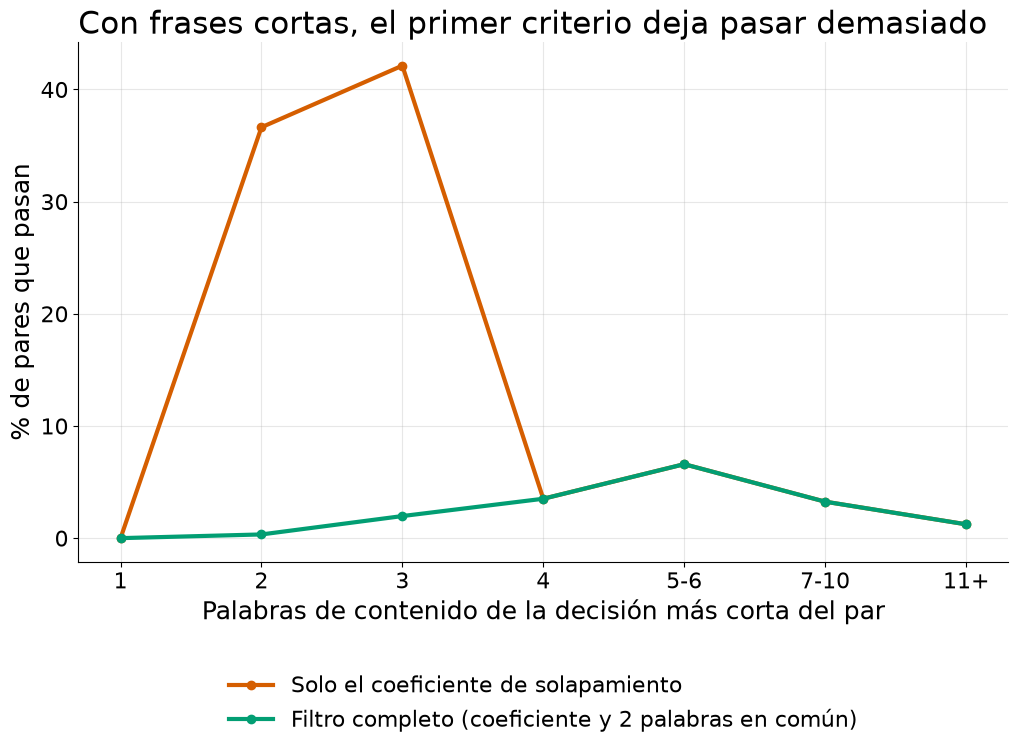

,bin,n,n_true_coef,rate_coef,n_true_filtro,rate_filtro
0,1,18,0,0.0000,0,0.0000
1,2,303,111,0.3663,1,0.0033
2,3,1270,535,0.4213,25,0.0197
3,4,484,17,0.0351,17,0.0351
4,5-6,546,36,0.0659,36,0.0659
5,7-10,369,12,0.0325,12,0.0325
6,11+,81,1,0.0123,1,0.0123


In [7]:
PAIR_F = eda.add_pair_features(PAIR)
BY_LENGTH = eda.rate_by_bin(
    PAIR_F, "shorter_tokens", "passes_overlap", eda.LEN_BINS, labels=eda.LEN_LABELS
).merge(
    eda.rate_by_bin(PAIR_F, "shorter_tokens", "is_candidate", eda.LEN_BINS, labels=eda.LEN_LABELS),
    on=["bin", "n"],
    suffixes=("_coef", "_filtro"),
)
with video_style():
    fig = plot_rate_lines(
        BY_LENGTH,
        {
            "Solo el coeficiente de solapamiento": "rate_coef",
            "Filtro completo (coeficiente y 2 palabras en común)": "rate_filtro",
        },
        xlabel="Palabras de contenido de la decisión más corta del par",
        ylabel="% de pares que pasan",
        title="Con frases cortas, el primer criterio deja pasar demasiado",
    )
    path = save_figure(fig, FIGURES_DIR / "eda-filtro-segun-longitud-de-frase.png")
    display(fig)
EXPORTED.append(path)
display(BY_LENGTH.round(4))

**Por qué esta figura.** Es la dificultad más importante que dejó el EDA para el diseño del
experimento. Las decisiones son frases muy cortas (la mitad tiene 5 palabras de contenido o menos) y el
filtro que propone pares de decisiones candidatos a estar relacionados se comporta de forma distinta
según el largo de la frase. Conecta de manera directa los datos con el problema de investigación.

**Mensaje en pantalla.** Cuando una de las dos decisiones tiene 3 palabras de contenido, el coeficiente
por sí solo deja pasar 42,1 % de los pares; el filtro completo, 2,0 %. Un criterio demasiado permisivo
y otro que puede descartar relaciones reales entre frases breves.

**Cómo influye en los siguientes pasos.** Se mantiene el punto de operación actual del filtro, se
documenta su sesgo hacia frases largas y, durante la anotación humana, se mide cuántas relaciones reales
descarta (recall) antes de apoyarse en él.

*Origen en el notebook 03: §10.3 (pregunta P2) y hallazgos 13 y 14 de §11.1.*

---

# Resumen

## Figuras elegidas

| Figura | Archivo (en `docs/entregables/figuras/`) | Mensaje | Criterio de la rúbrica | Origen en 03 |
|---|---|---|---|---|
| 1 | `eda-estructura-de-los-datos.png` | Cinco niveles de datos; pocas series, muchos pares | Organización | §1.2, §2.1 |
| 2 | `eda-decisiones-sin-evidencia-por-posicion.png` | 26 decisiones sin evidencia, más en reuniones tardías; se marcan, no se imputan | Limpieza inicial | §3, §5.5 |
| 3 | `eda-decisiones-por-posicion.png` | La primera reunión tiene la mitad de decisiones | Hallazgo descriptivo | §9 |
| 4 | `eda-embudo-del-filtro-lexico.png` | 3.071 pares → 92 con el filtro; ≈ 77 h → ≈ 2,3 h; el par de control se conserva | Decisión metodológica clave | §10.4, D9 |
| 5 | `eda-filtro-segun-longitud-de-frase.png` | El filtro de pares depende del largo de la frase | Dificultad y consecuencia | §10.3 |

Las cinco figuras pertenecen al conjunto principal; el máximo de 8 minutos lo fija la rúbrica y, si el
guion no alcanza, la figura 3 es la más prescindible.

## Figuras del notebook 03 que quedan fuera

- **Matriz de valores faltantes (§3.1):** su mensaje se resume mejor con la figura 2.
- **Histogramas y diagramas de caja de reuniones, decisiones, pares y hablantes (§4):** son descripción
  básica sin conexión directa con el problema; pasan a anexos.
- **Barras de variables categóricas y mosaicos (§4.4, §6.2):** demasiado densos para una grabación; el
  resultado relevante (la estructura no depende del sitio) cabe en una frase.
- **Dispersión, matriz de dispersión y correlaciones (§6.1, §7):** hallazgos de apoyo (palabras y
  duración con r = 0,92) que no cambian los pasos siguientes.
- **Comparaciones por sitio y rol (§6.3):** diferencias pequeñas; van a anexos.
- **PCA y agrupamiento (§8):** no se encontró estructura, un resultado negativo que no necesita imagen.
- **Trayectorias temporales por serie (§9):** la figura 3 muestra lo esencial con menos ruido.
- **Ventana de contexto (§10.1) y cuadrícula completa de sensibilidad del filtro (§10.4):** relevantes
  para el diseño, pero técnicas para un video de 8 minutos; de la sensibilidad solo entra el recorrido
  hasta el punto de operación elegido (figura 4).
- **Valores atípicos en el tamaño de las reuniones (§5):** no se conecta con el problema de investigación; la decisión sobre los atípicos (conservarlos todos) sigue documentada en el notebook 03, §5.
- **Autoría por rol (§10.5):** el hallazgo (el PM aporta 47 % de la evidencia) está mezclado con su
  volumen de habla y requiere un análisis adicional antes de mostrarse.

## Reproducir

```bash
uv run jupyter nbconvert --to notebook --execute --inplace \
  --ExecutePreprocessor.timeout=900 notebooks/11-jss-figuras-video-eda.ipynb
```